In [269]:
# comment

# **Exploratory Data Analysis**

## Challenge Rhine freight

## 1. Setup
### 1.1 Package instalation

Install packages (remove # and run). Only needed one time.

In [270]:
#!pip install pandas matplotlib seaborn scikit-learn numpy

### 1.2 Imports and paths 

In [271]:
# Imports
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import phik

# Paths
DATA_DIR = Path("..") / "data"
CHARTS_DIR = Path("..") / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)


## 2. Load Datasets

In [272]:
# Rhine Freight Data
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_freight['Date'] = pd.to_datetime(df_freight['Date'], dayfirst=True) 
# Drop empty rows
df_freight.dropna(subset=['Date'])

# Weather Data
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")
df_weather['date'] = pd.to_datetime(df_weather['date'], dayfirst=True) # dates are dd/mm/yyyy
# Drop empty rows
df_weather.dropna(subset=['date'])

,date,avg_uv_index,avgtemp,cloudcover,dewpoint,feelslike,heatindex,humidity,maxtemp,mintemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2009-01-01,1.0,-1.0,17.0,-4.0,-6.0,-3.0,95.0,2.0,-5.0,...,0.0,1.0,7.0,113.0,['Clear'],48.0,NE,10.0,-6.0,19.0
1,2009-01-02,1.0,-3.0,63.0,-5.0,-9.0,-3.0,88.0,-2.0,-4.0,...,0.0,1.0,10.0,119.0,['Cloudy'],54.0,NE,17.0,-9.0,26.0
2,2009-01-03,1.0,-7.0,7.0,-12.0,-12.0,-9.0,78.0,-4.0,-11.0,...,0.0,1.0,10.0,113.0,['Clear'],67.0,ENE,6.0,-12.0,13.0
3,2009-01-04,1.0,-8.0,19.0,-12.0,-10.0,-8.0,74.0,-4.0,-10.0,...,0.0,1.0,10.0,116.0,['Partly cloudy'],264.0,W,4.0,-10.0,9.0
4,2009-01-05,1.0,-7.0,74.0,-8.0,-11.0,-6.0,89.0,-5.0,-8.0,...,0.0,1.0,10.0,122.0,['Overcast'],56.0,NE,10.0,-11.0,17.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3647,2018-12-27,1.0,1.0,48.0,-11.0,-1.0,1.0,40.0,4.0,-1.0,...,0.0,1.0,10.0,116.0,['Partly cloudy'],190.0,S,6.0,-1.0,11.0
3648,2018-12-28,1.0,1.0,10.0,-2.0,0.0,1.0,79.0,4.0,0.0,...,0.0,1.0,10.0,113.0,['Clear'],225.0,SW,3.0,0.0,5.0
3649,2018-12-29,1.0,0.0,8.0,-2.0,-2.0,0.0,85.0,3.0,-1.0,...,0.0,1.0,10.0,113.0,['Clear'],205.0,SSW,6.0,-2.0,12.0
3650,2018-12-30,1.0,2.0,53.0,0.0,2.0,2.0,86.0,4.0,1.0,...,0.0,1.0,10.0,116.0,['Partly cloudy'],179.0,S,3.0,2.0,7.0


### **2.1 Rhine Freight dataset -  Prices and Rhine water level**

In [273]:
# Visualize structure of the data
df_freight

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN
...,...,...,...,...,...,...,...,...
1708,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1709,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1710,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1711,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1.1 Preliminary analysis of the dataset

In [274]:
# Dataset shape visualization
print(f"Dataset shape: {df_freight.shape}")

# Check for completely empty rows in df_freight
empty_rows = df_freight.isna().all(axis=1).sum()
print(f"Number of completely empty rows in df_freight: {empty_rows}")

#Drop completely empty rows from df_freight
df_freight = df_freight.dropna(how="all")
print(f"Dataset shape after dropping empty rows: {df_freight.shape}")

Dataset shape: (1713, 8)
Number of completely empty rows in df_freight: 244
Dataset shape after dropping empty rows: (1469, 8)


#### Dataset Overview

The original dataset contained **1,713 rows** and **8 columns**.

During the missing values analysis, it was observed that the final rows of the dataset were completely empty (i.e., all columns contained missing values).

A total of **244 rows** were removed because they contained no information. After dropping these fully empty rows, the dataset size was reduced to **1,469 rows**, while the number of columns remained unchanged.


After cleaning the completly empty rows some variables still have missing values, especially ``freight_ar``.

In [275]:
missing_summary = pd.DataFrame({
    "Missing Count": df_freight.isna().sum(),
    "Missing %": (df_freight.isna().mean() * 100).round(2)
}).sort_values("Missing %", ascending=False)

missing_summary

,Missing Count,Missing %
freight_ar,746,50.78
Freight,15,1.02
Kaub_level,13,0.88
Date,0,0.00
Brent_flat,0,0.00
Mogas_Flat,0,0.00
Heating_Flat,0,0.00
Diesel_Flat,0,0.00


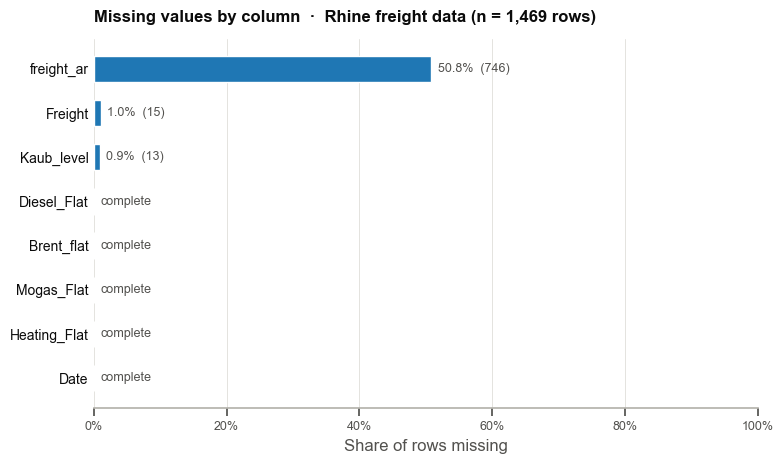

In [276]:
# plot: missing values per column ---
plot_df = missing_summary.sort_values("Missing %")          # largest at the top
n_rows = len(df_freight)
colors = np.where(plot_df["Missing %"] > 0, "tab:blue", "tab:grey")   # blue = has gaps, grey = complete

fig, ax = plt.subplots(figsize=(8, 0.45 * len(plot_df) + 1.2))
bars = ax.barh(plot_df.index, plot_df["Missing %"], color=colors, height=0.6)

# value labels: "% (count)" at the end of each bar
for bar, pct, cnt in zip(bars, plot_df["Missing %"], plot_df["Missing Count"]):
    label = "complete" if cnt == 0 else f"{pct:.1f}%  ({cnt:,})"
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, label,
            va="center", ha="left", fontsize=9, color="#52514e")

ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.set_xlabel("Share of rows missing", color="#52514e")
ax.set_title(f"Missing values by column  ·  Rhine freight data (n = {n_rows:,} rows)",
             loc="left", fontsize=12, fontweight="bold", color="#0b0b0b", pad=12)

ax.grid(axis="x", color="#e4e3df", linewidth=0.7)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#b5b3ad")
ax.tick_params(axis="y", length=0, labelsize=10, colors="#0b0b0b")
ax.tick_params(axis="x", colors="#52514e", labelsize=9)

plt.tight_layout()
plt.show()




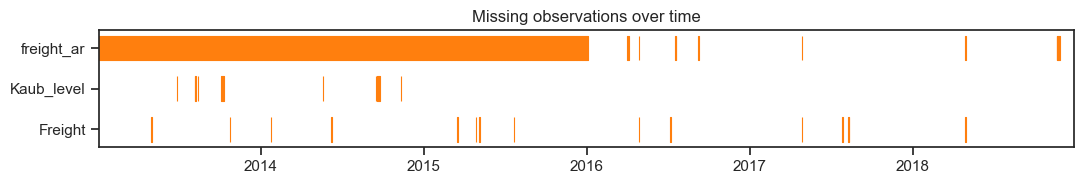

In [277]:
cols = ["Freight", "Kaub_level", "freight_ar"]
dates = pd.to_datetime(df_freight["Date"], dayfirst=True)
width = (dates.shift(-1) - dates).dt.days.fillna(1)   # each row spans until the next row (bridges weekends/holidays)

fig, ax = plt.subplots(figsize=(11, 2))
for i, c in enumerate(cols):
    m = df_freight[c].isna()
    ax.broken_barh(list(zip(mdates.date2num(dates[m]), width[m])), (i - 0.3, 0.6),
                   facecolor="tab:orange", edgecolor="tab:orange", lw=0.8)
ax.set_yticks(range(len(cols)), cols)
ax.set_xlim(mdates.date2num(dates.min()), mdates.date2num(dates.max()))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Missing observations over time")
plt.tight_layout(); plt.show()

The variables `Freight` and `Kaub_level` still contain a small number of missing values, representing a negligible proportion of the dataset. On the other hand, 51% of the observations don't have any recorded value for `freight_ar`.

In [278]:
df_freight.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Date,1469,2016-01-01 04:48:11.763104,2013-01-03 00:00:00,2014-07-08 00:00:00,2016-01-04 00:00:00,2017-07-03 00:00:00,2018-12-28 00:00:00,NaN
Freight,1454.0,66.74088,31.8,40.8,45.3,60.3,360.45,54.903678
Mogas_Flat,1469.0,471.307495,265.988761,407.779598,482.88861,536.367611,643.154358,76.829817
Brent_flat,1469.0,175.428168,71.486202,132.274233,162.397599,230.795073,267.888999,49.417972
Diesel_Flat,1469.0,452.550514,235.426759,393.15444,466.190525,511.022014,592.948663,76.061052
Heating_Flat,1469.0,429.251464,197.540995,366.270631,436.102649,495.777277,579.071651,81.264952
Kaub_level,1456.0,211.656593,25.0,138.0,198.0,264.0,716.0,106.91636
freight_ar,723.0,3.254177,1.73,2.435,2.87,3.42,8.92,1.410743


### **2.2 Weather Dataset**

In [279]:
# Visualize structure of the data
df_weather

,date,avg_uv_index,avgtemp,cloudcover,dewpoint,feelslike,heatindex,humidity,maxtemp,mintemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2009-01-01,1.0,-1.0,17.0,-4.0,-6.0,-3.0,95.0,2.0,-5.0,...,0.0,1.0,7.0,113.0,['Clear'],48.0,NE,10.0,-6.0,19.0
1,2009-01-02,1.0,-3.0,63.0,-5.0,-9.0,-3.0,88.0,-2.0,-4.0,...,0.0,1.0,10.0,119.0,['Cloudy'],54.0,NE,17.0,-9.0,26.0
2,2009-01-03,1.0,-7.0,7.0,-12.0,-12.0,-9.0,78.0,-4.0,-11.0,...,0.0,1.0,10.0,113.0,['Clear'],67.0,ENE,6.0,-12.0,13.0
3,2009-01-04,1.0,-8.0,19.0,-12.0,-10.0,-8.0,74.0,-4.0,-10.0,...,0.0,1.0,10.0,116.0,['Partly cloudy'],264.0,W,4.0,-10.0,9.0
4,2009-01-05,1.0,-7.0,74.0,-8.0,-11.0,-6.0,89.0,-5.0,-8.0,...,0.0,1.0,10.0,122.0,['Overcast'],56.0,NE,10.0,-11.0,17.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4012,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4013,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4014,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4015,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.2.1 Preliminary analysis of the dataset

In [280]:
# Dataset shape visualization
print(f"Dataset shape: {df_weather.shape}")

# Check for completely empty rows in df_weather
empty_rows = df_weather.isna().all(axis=1).sum()
print(f"Number of completely empty rows in df_weather: {empty_rows}")

#Drop completely empty rows from df_weather
df_weather = df_weather.dropna(how="all")
print(f"Dataset shape after dropping empty rows: {df_weather.shape}")

Dataset shape: (4017, 25)
Number of completely empty rows in df_weather: 365
Dataset shape after dropping empty rows: (3652, 25)


#### Dataset Overview

The original dataset contained **4,017 rows** and **25 columns**.

During the missing values analysis, it was observed a similar situation to the previous dataset, where the final rows of the dataset were completely empty (i.e., all columns contained missing values).

A total of **365 rows** were removed because they contained no information. After dropping these fully empty rows, the dataset size was reduced to **3,652 rows**, while the number of columns remained unchanged.


After cleaning the completly empty rows no more missing values remained.

In [281]:
missing_summary = pd.DataFrame({
    "Missing Count": df_weather.isna().sum(),
    "Missing %": (df_weather.isna().mean() * 100).round(2)
}).sort_values("Missing %", ascending=False)

missing_summary

,Missing Count,Missing %
date,0,0.0
avg_uv_index,0,0.0
avgtemp,0,0.0
cloudcover,0,0.0
dewpoint,0,0.0
feelslike,0,0.0
heatindex,0,0.0
humidity,0,0.0
maxtemp,0,0.0
mintemp,0,0.0


In [282]:
df_weather.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
date,3652,2013-12-31 12:00:00,2009-01-01 00:00:00,2011-07-02 18:00:00,2013-12-31 12:00:00,2016-07-01 06:00:00,2018-12-31 00:00:00,NaN
avg_uv_index,3652.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
avgtemp,3652.0,9.167306,-14.0,3.0,9.0,15.0,28.0,7.366278
cloudcover,3652.0,38.84529,0.0,10.0,30.0,63.0,100.0,31.969881
dewpoint,3652.0,6.733844,-17.0,1.0,7.0,12.0,24.0,7.164333
feelslike,3652.0,8.036966,-19.0,1.0,8.0,15.0,34.0,8.941117
heatindex,3652.0,9.326944,-15.0,3.0,9.0,15.0,34.0,8.054315
humidity,3652.0,85.778204,40.0,81.0,88.0,93.0,100.0,10.198232
maxtemp,3652.0,13.760131,-10.0,7.0,14.0,20.0,34.0,8.440162
mintemp,3652.0,4.971796,-19.0,0.0,5.0,10.0,22.0,6.510302


### Sanity checks

In [283]:
# Constant variables: columns with only one unique value (e.g. all zeros, or all NaN)
const = [c for c in df_weather.columns if df_weather[c].nunique() == 1]
print('constant columns:', const)

# sanity checks
df_weather['date'] = pd.to_datetime(df_weather['date'], dayfirst=True)   # dates are dd/mm/yyyy
df_weather['year'] = df_weather['date'].dt.year
print('maxtemp < mintemp:', (df_weather['maxtemp'] < df_weather['mintemp']).sum())
print('avgtemp outside [min,max]:', ((df_weather['avgtemp'] > df_weather['maxtemp']) | (df_weather['avgtemp'] < df_weather['mintemp'])).sum())
print('days with precip > 0:', (df_weather['precip'] > 0).sum(), 'of', len(df_weather))
print('days with snow  > 0:', (df_weather['totalsnow'] > 0).sum())
df_weather['year'] = df_weather['date'].dt.year
display(df_weather.groupby('year')['precip'].sum().rename('Total precip annual').to_frame().T)
print(df_weather['weather_descriptions'].value_counts())

constant columns: ['avg_uv_index', 'uv_index']
maxtemp < mintemp: 0
avgtemp outside [min,max]: 0
days with precip > 0: 34 of 3652
days with snow  > 0: 236


C:\Users\PedroJorge\AppData\Local\Temp\ipykernel_6996\1977194025.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_weather['date'] = pd.to_datetime(df_weather['date'], dayfirst=True)   # dates are dd/mm/yyyy
C:\Users\PedroJorge\AppData\Local\Temp\ipykernel_6996\1977194025.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_weather['year'] = df_weather['date'].dt.year
C:\Users\PedroJorge\AppData\Local\Temp\ipykernel_6996\1977194025.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy

year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
Total precip annual,0.0,0.0,3.6,6.5,0.6,1.5,2.0,1.1,0.0,0.1


weather_descriptions
['Clear']                             1640
['Partly cloudy']                      737
['Mist']                               364
['Overcast']                           316
['Cloudy']                             281
['Fog']                                153
['Thundery outbreaks possible']         76
['Freezing fog']                        47
['Patchy rain possible']                17
['Light rain shower']                    6
['Moderate or heavy rain shower']        5
['Moderate rain']                        3
['Torrential rain shower']               2
['Light rain']                           2
['Heavy rain at times']                  1
['Patchy light rain']                    1
['Patchy light rain with thunder']       1
Name: count, dtype: int64


**Data-quality red flags:**
- `uv_index` and `avg_uv_index` are constant (=1) → drop.
- `precip` is essentially empty: non-zero on only 34 of 3,652 days, annual totals of 0–6.5 mm. Basel's real annual rainfall is in the order of 800+ mm, so this column is **not usable** — and rain is the variable you'd most want for river levels.
- Description labels are implausibly dry for the same reason (≈45 % "Clear", hardly any rain labels).
- `sunhour` takes few distinct values per month (e.g. 14.5 h appears 500 times) — looks modelled/capped rather than measured.
- Temperature fields are internally consistent (no max<min), but `feelslike`, `heatindex`, `windchill`, `dewpoint` are all ρ ≥ 0.96 with `avgtemp` — redundant for modelling.

## 3. Time Series analysis

### Rhine Freight Dataset

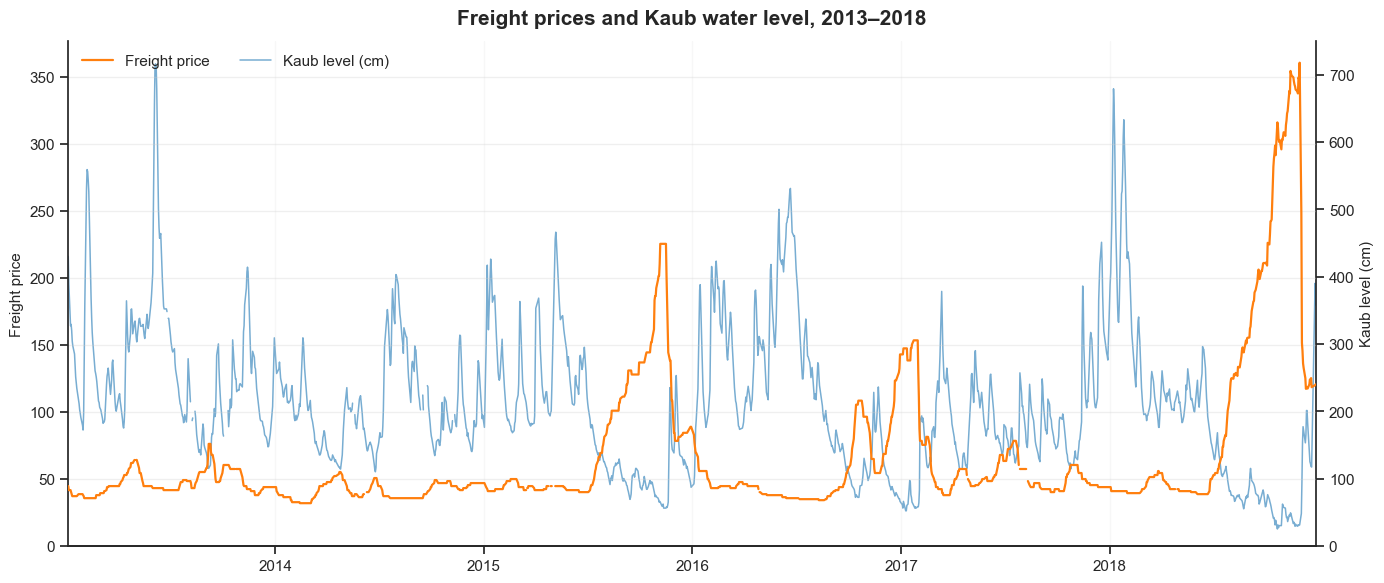

In [284]:
dates = pd.to_datetime(df_freight["Date"], dayfirst=True)
C_FREIGHT, C_KAUB = "tab:orange", "tab:blue"

fig, ax1 = plt.subplots(figsize=(14, 6))
ax2 = ax1.twinx()   # second y-axis sharing the same x-axis

l1, = ax1.plot(dates, df_freight["Freight"], lw=1.6, color=C_FREIGHT, label="Freight price", zorder=3)
l2, = ax2.plot(dates, df_freight["Kaub_level"], lw=1.1, color=C_KAUB, alpha=0.6, label="Kaub level (cm)")
ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)   # freight drawn on top

ax1.set_ylabel("Freight price", fontsize=11)
ax2.set_ylabel("Kaub level (cm)", fontsize=11)
ax1.spines["top"].set_visible(False); ax2.spines["top"].set_visible(False)
ax2.spines["left"].set_visible(False); ax1.spines["right"].set_visible(False)

ax1.set_ylim(0, None); ax2.set_ylim(0, None)   # both axes start at zero
ax1.grid(axis="y", alpha=0.3); ax1.grid(axis="x", alpha=0.15)
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.set_xlim(dates.min(), dates.max())

ax1.legend(handles=[l1, l2], loc="upper left", frameon=False, ncol=2)
ax1.set_title("Freight prices and Kaub water level, 2013–2018", loc="center", fontsize=15, fontweight="bold", pad=12)
fig.tight_layout()
plt.show()

Lower Kaub River levels appear to be associated with higher freight prices, suggesting a negative relationship between river water levels and transportation costs.

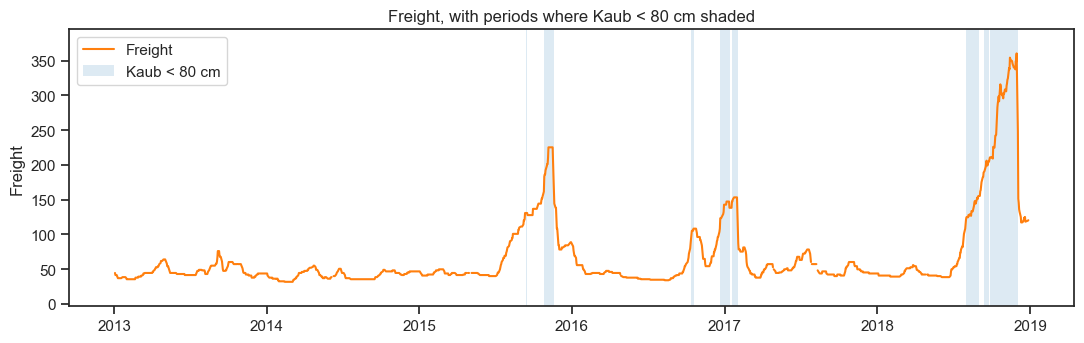

In [285]:
dates = pd.to_datetime(df_freight["Date"], dayfirst=True)
low = df_freight["Kaub_level"].ffill() < 80

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(dates, df_freight["Freight"], color="tab:orange", lw=1.5, label="Freight")
ax.fill_between(dates, 0, 1, where=low, color="tab:blue", alpha=0.15,
                transform=ax.get_xaxis_transform(), lw=0, label="Kaub < 80 cm")   # shade full height where Kaub is low
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("Freight")
ax.set_title("Freight, with periods where Kaub < 80 cm shaded", loc="center")
ax.legend()
plt.tight_layout(); plt.show()

The low-water reference level for the Kaub River is approximately 80 cm. When the river level falls below this threshold, freight prices tend to reach their highest values.

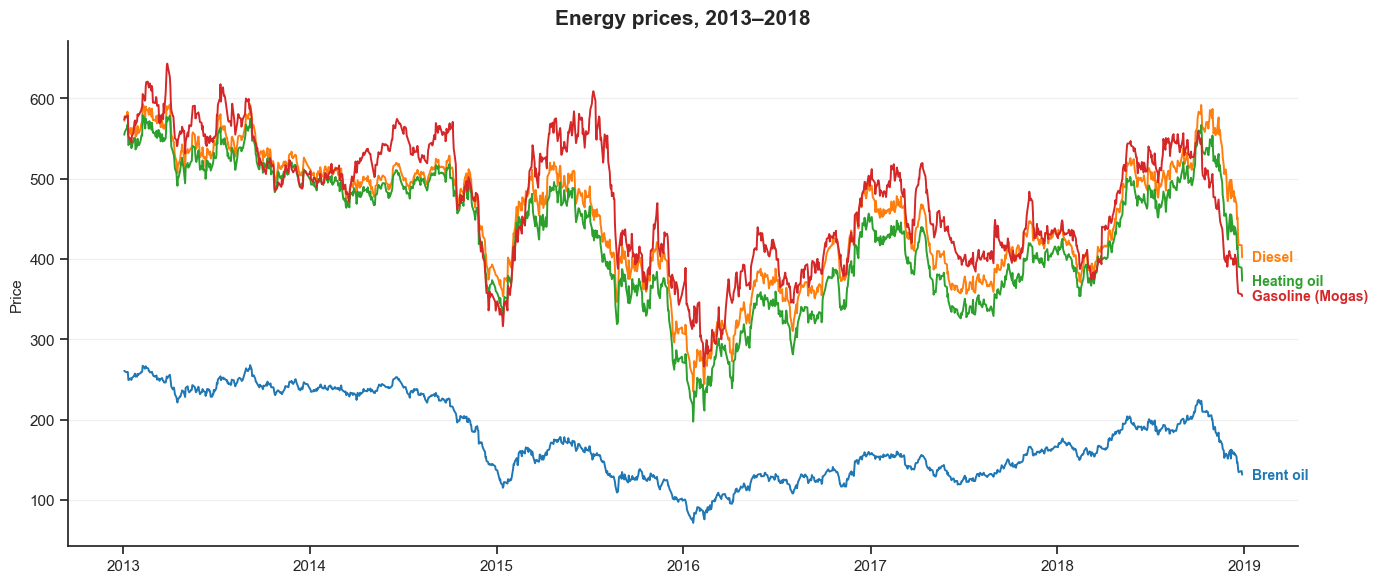

In [286]:
sns.set_theme(style="ticks")

cols = {"Brent_flat": "Brent oil", "Diesel_Flat": "Diesel", "Heating_Flat": "Heating oil", "Mogas_Flat": "Gasoline (Mogas)"}
data = (df_freight.assign(Date=pd.to_datetime(df_freight["Date"], dayfirst=True))
        .set_index("Date")[list(cols)].rename(columns=cols))

fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=data, palette="tab10", linewidth=1.4, dashes=False, ax=ax)

# label each line at its right end instead of a legend box
for (name, s), color in zip(data.items(), sns.color_palette("tab10")):
    ax.text(s.index[-1] + pd.Timedelta(days=20), s.iloc[-1], name, color=color,
            va="center", fontsize=10, fontweight="bold")
ax.get_legend().remove()

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("")
ax.set_ylabel("Price", fontsize=11)
ax.grid(axis="y", alpha=0.3)
sns.despine(ax=ax)
ax.set_title("Energy prices, 2013–2018", fontsize=15, fontweight="bold", loc="center", pad=12)
plt.tight_layout()
plt.show()

Similar fuel prices for a set of different fuels

#### Distributions

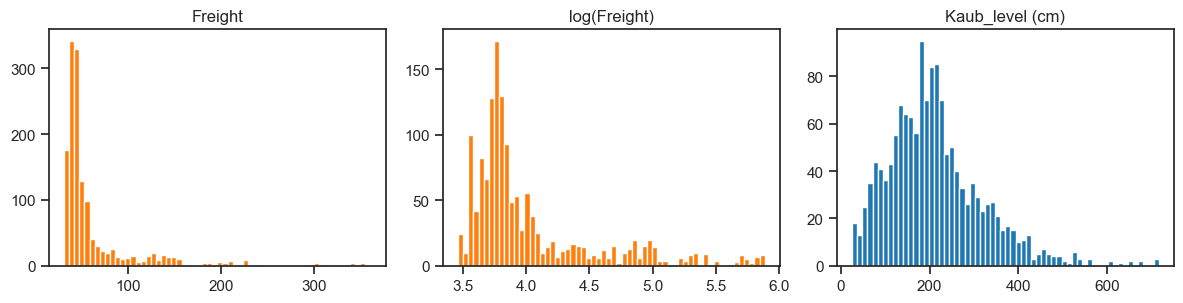

Freight skew: 3.09 | log skew: 1.71


In [287]:

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].hist(df_freight['Freight'].dropna(), bins=60, color="tab:orange"); axes[0].set_title('Freight')
axes[1].hist(np.log(df_freight['Freight'].dropna()), bins=60, color="tab:orange"); axes[1].set_title('log(Freight)')
axes[2].hist(df_freight['Kaub_level'].dropna(), bins=60, color="tab:blue"); axes[2].set_title('Kaub_level (cm)')
plt.tight_layout(); plt.show()
print('Freight skew:', df_freight['Freight'].skew().round(2), '| log skew:', np.log(df_freight['Freight']).skew().round(2))

#### Correlations and seasonality

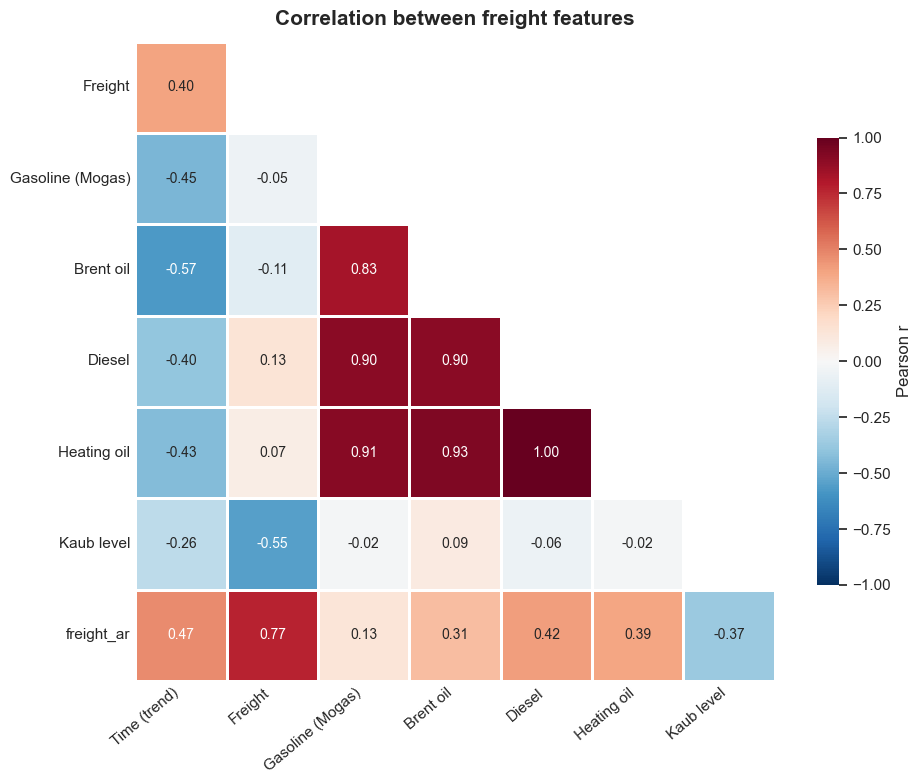

In [288]:
correlation_data = df_freight.copy()

correlation_data["Date"] = pd.to_datetime(correlation_data["Date"], dayfirst=True)   # dates are dd/mm/yyyy
correlation_data = correlation_data.dropna(subset=["Date"])
correlation_data["Date"] = correlation_data["Date"].map(lambda date: date.toordinal())   # time trend

labels = {"Date": "Time (trend)", "Freight": "Freight", "Kaub_level": "Kaub level",
          "Brent_flat": "Brent oil", "Diesel_Flat": "Diesel", "Heating_Flat": "Heating oil",
          "Mogas_Flat": "Gasoline (Mogas)", "freight_ar": "freight_ar"}
correlation_matrix = correlation_data.rename(columns=labels).corr(method="pearson")

# Generate a mask for the upper triangle; drop the empty first row / last column
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
corr = correlation_matrix.iloc[1:, :-1]
mask = mask[1:, :-1]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr,
    mask=mask,       # Hides the upper triangle
    annot=True,
    fmt=".2f",
    annot_kws={"size": 10},
    cmap="RdBu_r",   # diverging: blue = negative, red = positive, white = 0
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=1,
    linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson r"},
    ax=ax,
)
ax.tick_params(length=0)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
ax.set_title("Correlation between freight features", fontsize=15, fontweight="bold", pad=12, loc="center")
fig.tight_layout()
plt.show()

The correlation map shows three distinct groups of variables:

1. The four energy prices are strongly inter-correlated (r = 0.83–1.00), with diesel and heating oil being almost identical (r ≈ 1.00), reflecting their shared dependence on crude oil markets. Including more than one of them in a model would therefore add redundant information and introduce multicollinearity.


2. Freight shows virtually no linear relationship with energy prices (|r| ≤ 0.13), suggesting that fuel costs are not the main driver of freight rates over this period. Instead, freight is most strongly associated with the Kaub water level (r = −0.55): lower river levels coincide with higher freight prices, consistent with vessels having to reduce their loads during low-water periods. Because this relationship is non-linear, with freight remaining stable at normal levels and rising sharply only below roughly 100–130 cm, the Pearson coefficient likely underestimates its true strength (Spearman ρ ≈ −0.71).

3. The time trend reveals a moderate increase in freight (r = 0.40) and a decline in energy prices (r = −0.40 to −0.57) over 2013–2018. The rise in freight is largely driven by the severe low-water episodes of 2015 and 2018 rather than a steady upward trend, while the drop in energy prices reflects the 2014–2016 oil price collapse.

4. `freight_ar` is strongly correlated with freight (r = 0.77), but these values should be interpreted with caution, as the variable is only available from 2016 onward and its definition is not documented.


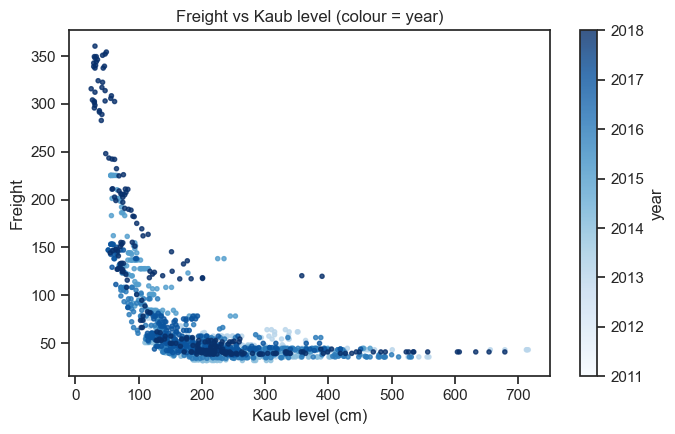

,count,median,mean,max
Kaub_level,,,,
"(0, 80]",131,192.3,205.1,360.4
"(80, 100]",64,120.3,122.5,210.8
"(100, 130]",124,77.6,80.0,169.5
"(130, 160]",163,50.6,55.8,145.5
"(160, 200]",252,46.0,48.7,136.0
"(200, 300]",449,41.6,43.4,138.3
"(300, 800]",258,41.6,42.4,120.4


In [289]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(df_freight['Kaub_level'], df_freight['Freight'], s=9, c=df_freight['Date'].dt.year, cmap='Blues', vmin=2011, alpha=0.8)
ax.set_xlabel('Kaub level (cm)'); ax.set_ylabel('Freight'); ax.set_title('Freight vs Kaub level (colour = year)')
plt.colorbar(sc, ax=ax, label='year'); plt.tight_layout(); plt.show()

bins = [0, 80, 100, 130, 160, 200, 300, 800]
df_freight.groupby(pd.cut(df_freight['Kaub_level'], bins), observed=True)['Freight'].agg(['count', 'median', 'mean', 'max']).round(1)

### Weather Dataset

#### Correlations and Seasonality

In [290]:
temps = ['avgtemp', 'maxtemp', 'mintemp', 'feelslike', 'heatindex', 'windchill', 'dewpoint']
df_weather[temps].corr().round(2)

,avgtemp,maxtemp,mintemp,feelslike,heatindex,windchill,dewpoint
avgtemp,1.00,0.98,0.96,0.98,0.98,0.98,0.96
maxtemp,0.98,1.00,0.91,0.97,0.97,0.97,0.94
mintemp,0.96,0.91,1.00,0.93,0.93,0.93,0.92
feelslike,0.98,0.97,0.93,1.00,0.99,1.00,0.96
heatindex,0.98,0.97,0.93,0.99,1.00,0.99,0.96
windchill,0.98,0.97,0.93,1.00,0.99,1.00,0.96
dewpoint,0.96,0.94,0.92,0.96,0.96,0.96,1.00


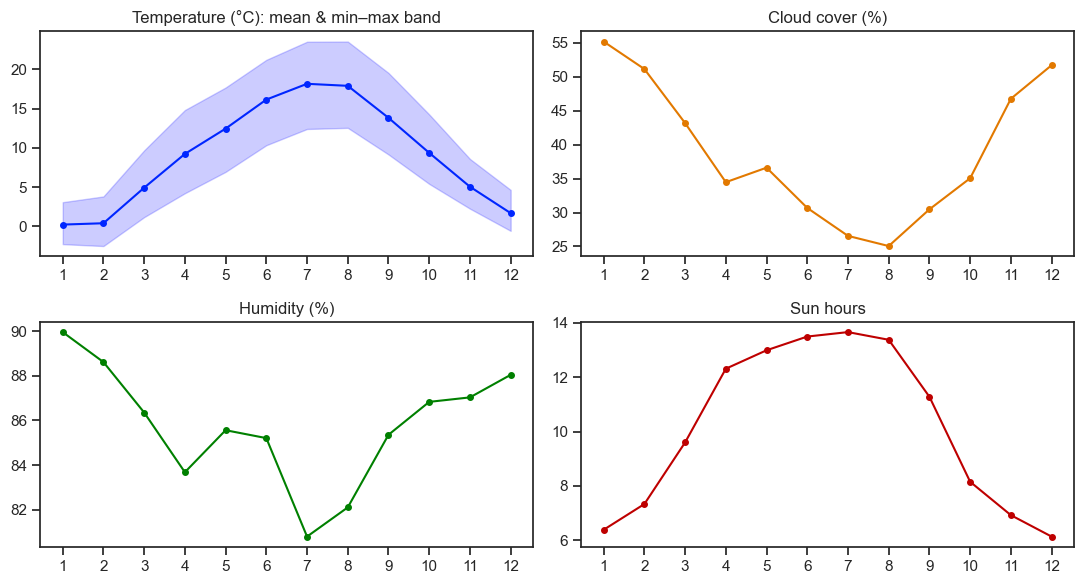

In [291]:
df_weather = df_weather.rename(columns={'date': 'Date'})
df_weather['Date'] = pd.to_datetime(df_weather['Date'])
df_weather['month'] = df_weather['Date'].dt.month

monthly = df_weather.groupby('month')[['avgtemp', 'maxtemp', 'mintemp', 'humidity', 'cloudcover', 'sunhour', 'wind_speed', 'pressure']].mean()
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
axes[0, 0].fill_between(monthly.index, monthly['mintemp'], monthly['maxtemp'], color='blue', alpha=0.2)
axes[0, 0].plot(monthly.index, monthly['avgtemp'], color="#0026FF", marker='o', ms=4); axes[0, 0].set_title('Temperature (°C): mean & min–max band')
axes[0, 1].plot(monthly.index, monthly['cloudcover'], color="#E27900", marker='o', ms=4); axes[0, 1].set_title('Cloud cover (%)')
axes[1, 0].plot(monthly.index, monthly['humidity'], color="#008000", marker='o', ms=4); axes[1, 0].set_title('Humidity (%)')
axes[1, 1].plot(monthly.index, monthly['sunhour'], color="#BE0000", marker='o', ms=4); axes[1, 1].set_title('Sun hours')
for a in axes.flat: a.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

In [292]:
df_weather.drop(columns=['month', 'year'], inplace=True)

Higher temperatures and sun hours during summer and lower for winter.

Humity and cloud cover higher during winnter and lower during summer.

These are the expected results

#### Correlations between temperature features

Features that represent temperature or percepted temperature exhibit the same patterns over time, and are highly correlated

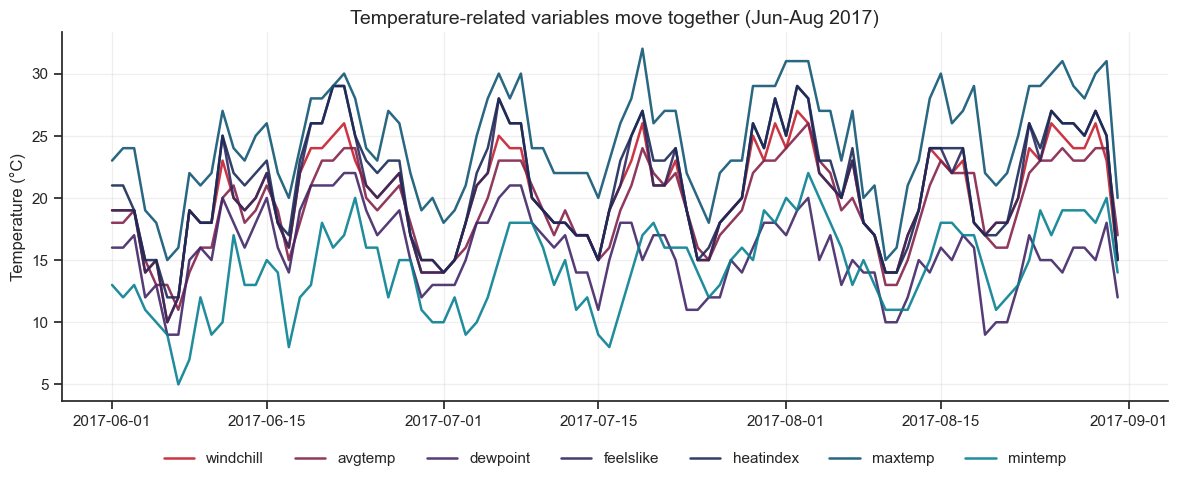

In [293]:
cols = ['windchill', 'avgtemp', 'dewpoint', 'feelslike', 'heatindex', 'maxtemp', 'mintemp']

cmap = LinearSegmentedColormap.from_list("closer", ["#c52030", "#422767", "#1c2a56", "#078091"])
colors = [cmap(i / (len(cols) - 1)) for i in range(len(cols))]

# Snippet from 2017: 3 months, enough to see the shared trend without clutter
d = df_weather.sort_values("Date")
d = d[(d["Date"] >= "2017-06-01") & (d["Date"] < "2017-09-01")]

fig, ax = plt.subplots(figsize=(12, 5))
for col, color in zip(cols, colors):
    ax.plot(d["Date"], d[col], label=col, color=color, lw=1.8, alpha=0.9)

ax.set_title("Temperature-related variables move together (Jun-Aug 2017)", fontsize=14)
ax.set_ylabel("Temperature (°C)")
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)

plt.tight_layout()
plt.show()

#### Precipitation

Precipitation values are unusual for this region, since it only rained for 34 days in 10 years. The results produced by this variable might not be reliable. 

Additional the signal this variable will carry is going to be negligible, since it is practically constant throughtout the dataset

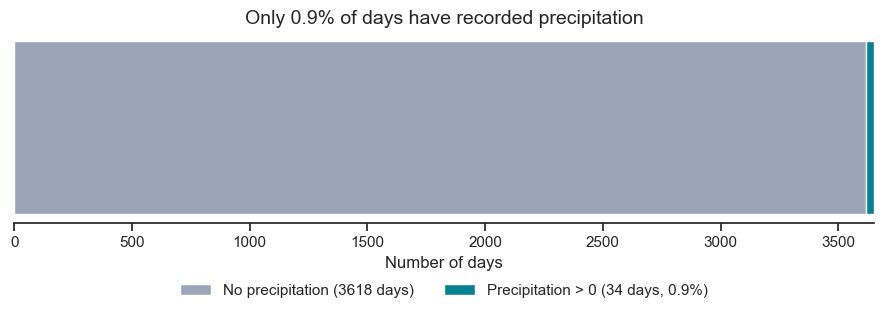

In [294]:
d = df_weather['precip']

n_total = len(d)
n_rain = (d > 0).sum()
n_dry = n_total - n_rain
pct_rain = n_rain / n_total * 100

fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.barh(['Days'], [n_dry], color="#9aa5b8", label=f"No precipitation ({n_dry} days)")
ax.barh(['Days'], [n_rain], left=[n_dry], color="#078091", label=f"Precipitation > 0 ({n_rain} days, {pct_rain:.1f}%)")

ax.set_title(f"Only {pct_rain:.1f}% of days have recorded precipitation", fontsize=14)
ax.set_xlabel("Number of days")
ax.set_xlim(0, n_total)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_yticks([])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)

plt.tight_layout()
plt.show()

## Joint datasets (df_freight + df_weather)

In [295]:
df_complete = pd.merge(df_freight, df_weather, on='Date', how='left')

#### Add the target column (Value of the freight in 5 days time)

In [296]:
# Price 5 rows ahead (the last 5 rows get NaN because they have no future)
df_complete['Freight_5days'] = df_complete['Freight'].shift(-5)

# Drop those last 5 rows
df_complete = df_complete.dropna(subset=['Freight_5days']).reset_index(drop=True)

##### Relatioship between Precipitation and Freight prices

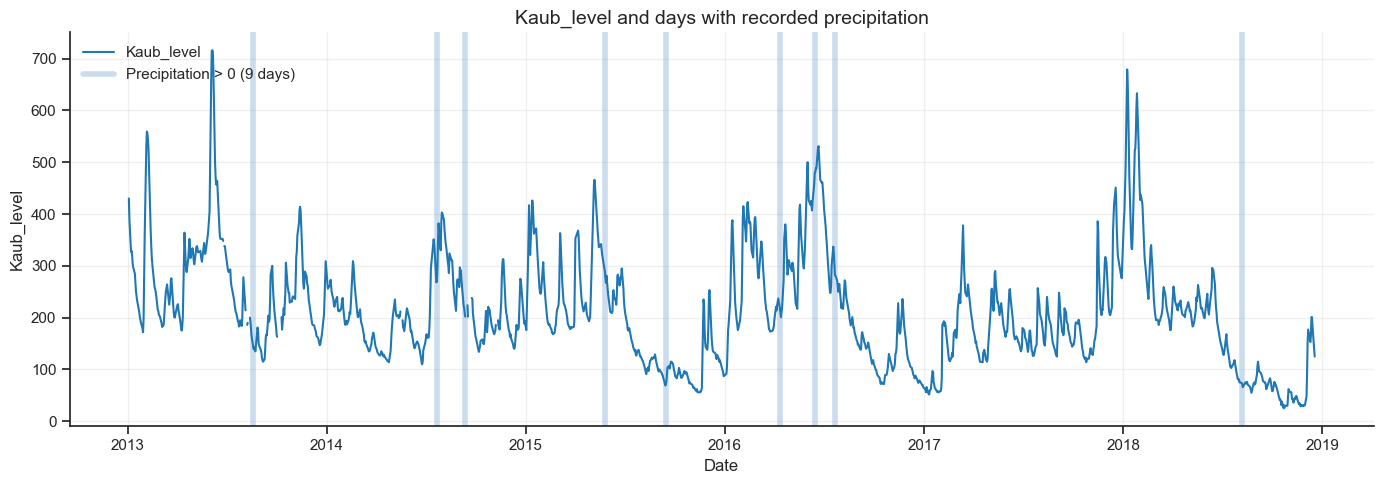

In [297]:
d = df_complete.sort_values('Date')
rain_dates = d.loc[d['precip'] > 0, 'Date']

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(d['Date'], df_complete['Kaub_level'], color="tab:blue", lw=1.5, label="Kaub_level", zorder=2)

# One thin vertical line per day with precipitation
for i, dt in enumerate(rain_dates):
    ax.axvline(dt, color="#689DCF", alpha=0.35, lw=4,
               label=f"Precipitation > 0 ({len(rain_dates)} days)" if i == 0 else None, zorder=1)

ax.set_title("Kaub_level and days with recorded precipitation", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Kaub_level")
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.show()

There is no apparent relationship between Kaul level and precipitation, further confirming that the variable is not reliable

#### Most correlated features to target

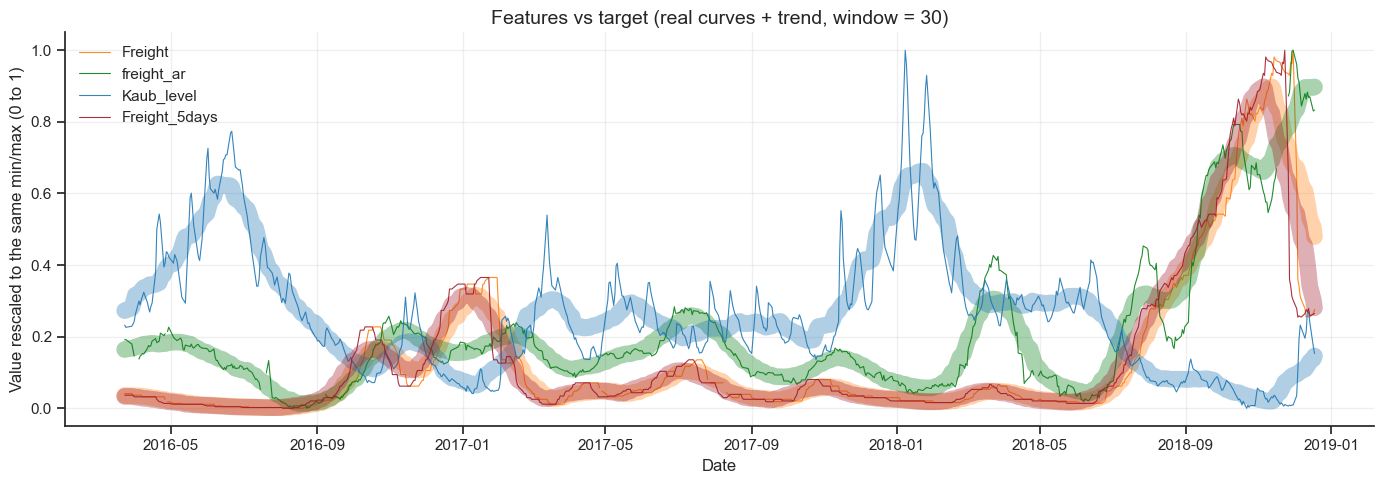

In [298]:
most_corr_target = ['Freight', 'freight_ar', 'Kaub_level']
target = ['Freight_5days']

trend_window = 30   # points averaged for the trend line

colors = {
    'Freight':       'tab:orange',
    'freight_ar':    "#097E18",
    'Kaub_level':    'tab:blue',
    'Freight_5days': "#A11C2A",
}

d = df_complete.sort_values('Date').set_index('Date').iloc[int(365*5/7*3):]
cols = most_corr_target + target

# Trend on the real values (centered: visualization only, never a model feature)
trend = d[cols].rolling(trend_window, center=True, min_periods=1).mean()

# Same transformation for curve and trend: every real curve spans exactly 0 to 1
lo, hi = d[cols].min(), d[cols].max()
raw_s   = (d[cols] - lo) / (hi - lo)
trend_s = (trend - lo) / (hi - lo)

fig, ax = plt.subplots(figsize=(14, 5))
for c in cols:
    ax.plot(raw_s.index, raw_s[c], color=colors[c], lw=0.8, alpha=0.9, label=c)
    ax.plot(trend_s.index, trend_s[c], color=colors[c], lw=12, alpha=0.35)

ax.set_title(f"Features vs target (real curves + trend, window = {trend_window})", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Value rescaled to the same min/max (0 to 1)")
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Traget is represented by red and the graph shows that the trends of freight prices are similar to the target and that the water level of kaub has opposite trends to the prices.

The curves are scaled in order to have a clearer picture of their relationship.

## Most determining weathr features to Kaub level

When looking at the correlation matrix most weather features present a correlation value to Kaub level around 0.2-0.3. Sunhour is the highest value (0.37)

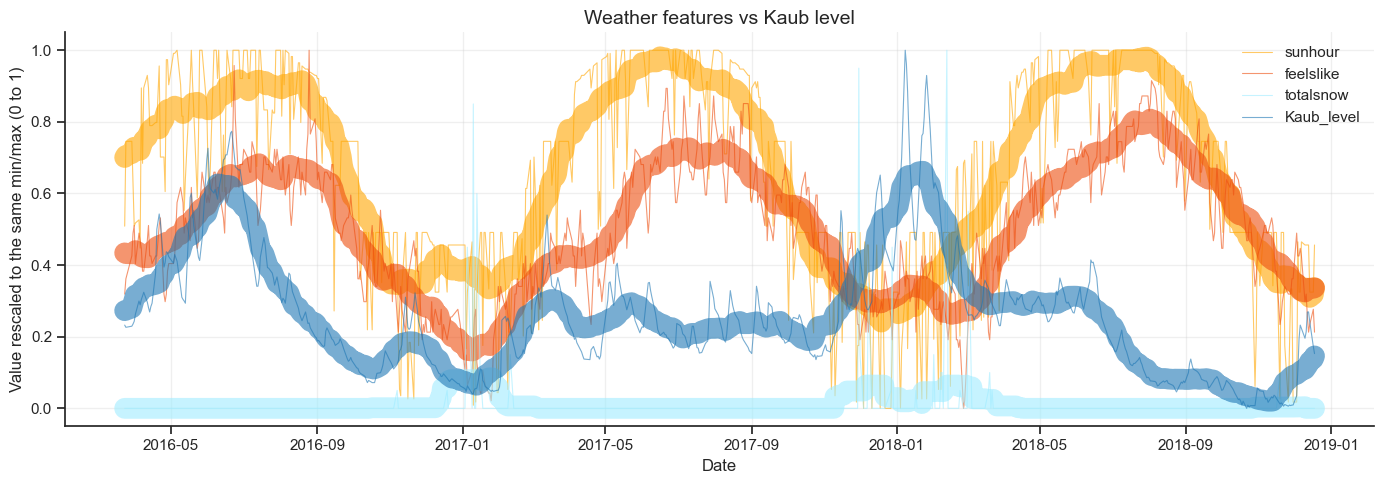

In [310]:
kaub_features = ['sunhour', 'feelslike', 'totalsnow']
target  = ['Kaub_level']

trend_window = 30   # points averaged for the trend line

colors = {
    'sunhour':       "#FFA600",
    'feelslike':    "#EE4E0F",
    'Kaub_level':    'tab:blue',
    'totalsnow': "#A0ECFF",
}

d = df_complete.sort_values('Date').set_index('Date').iloc[int(365*5/7*3):]
cols = kaub_features + target

# Trend on the real values (centered: visualization only, never a model feature)
trend = d[cols].rolling(trend_window, center=True, min_periods=1).mean()

# Same transformation for curve and trend: every real curve spans exactly 0 to 1
lo, hi = d[cols].min(), d[cols].max()
raw_s   = (d[cols] - lo) / (hi - lo)
trend_s = (trend - lo) / (hi - lo)

fig, ax = plt.subplots(figsize=(14, 5))
for c in cols:
    ax.plot(raw_s.index, raw_s[c], color=colors[c], lw=0.8, alpha=0.6, label=c)
    ax.plot(trend_s.index, trend_s[c], color=colors[c], lw=15, alpha=0.6)

ax.set_title(f"Weather features vs Kaub level", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Value rescaled to the same min/max (0 to 1)")
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Correlation matrix saved in the reports folder

interval columns not set, guessing: ['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat', 'Heating_Flat', 'Kaub_level', 'freight_ar', 'avg_uv_index', 'avgtemp', 'cloudcover', 'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp', 'moon_illumination', 'precip', 'pressure', 'sunhour', 'totalsnow', 'uv_index', 'visibility', 'weather_code', 'wind_degree', 'wind_speed', 'windchill', 'windgust', 'Freight_5days']


c:\Users\PedroJorge\AppData\Local\Programs\Python\Python312\Lib\site-packages\phik\data_quality.py:72: UserWarning: Not enough unique value for variable avg_uv_index for analysis 1. Dropping this column
  warnings.warn(
c:\Users\PedroJorge\AppData\Local\Programs\Python\Python312\Lib\site-packages\phik\data_quality.py:72: UserWarning: Not enough unique value for variable uv_index for analysis 1. Dropping this column
  warnings.warn(


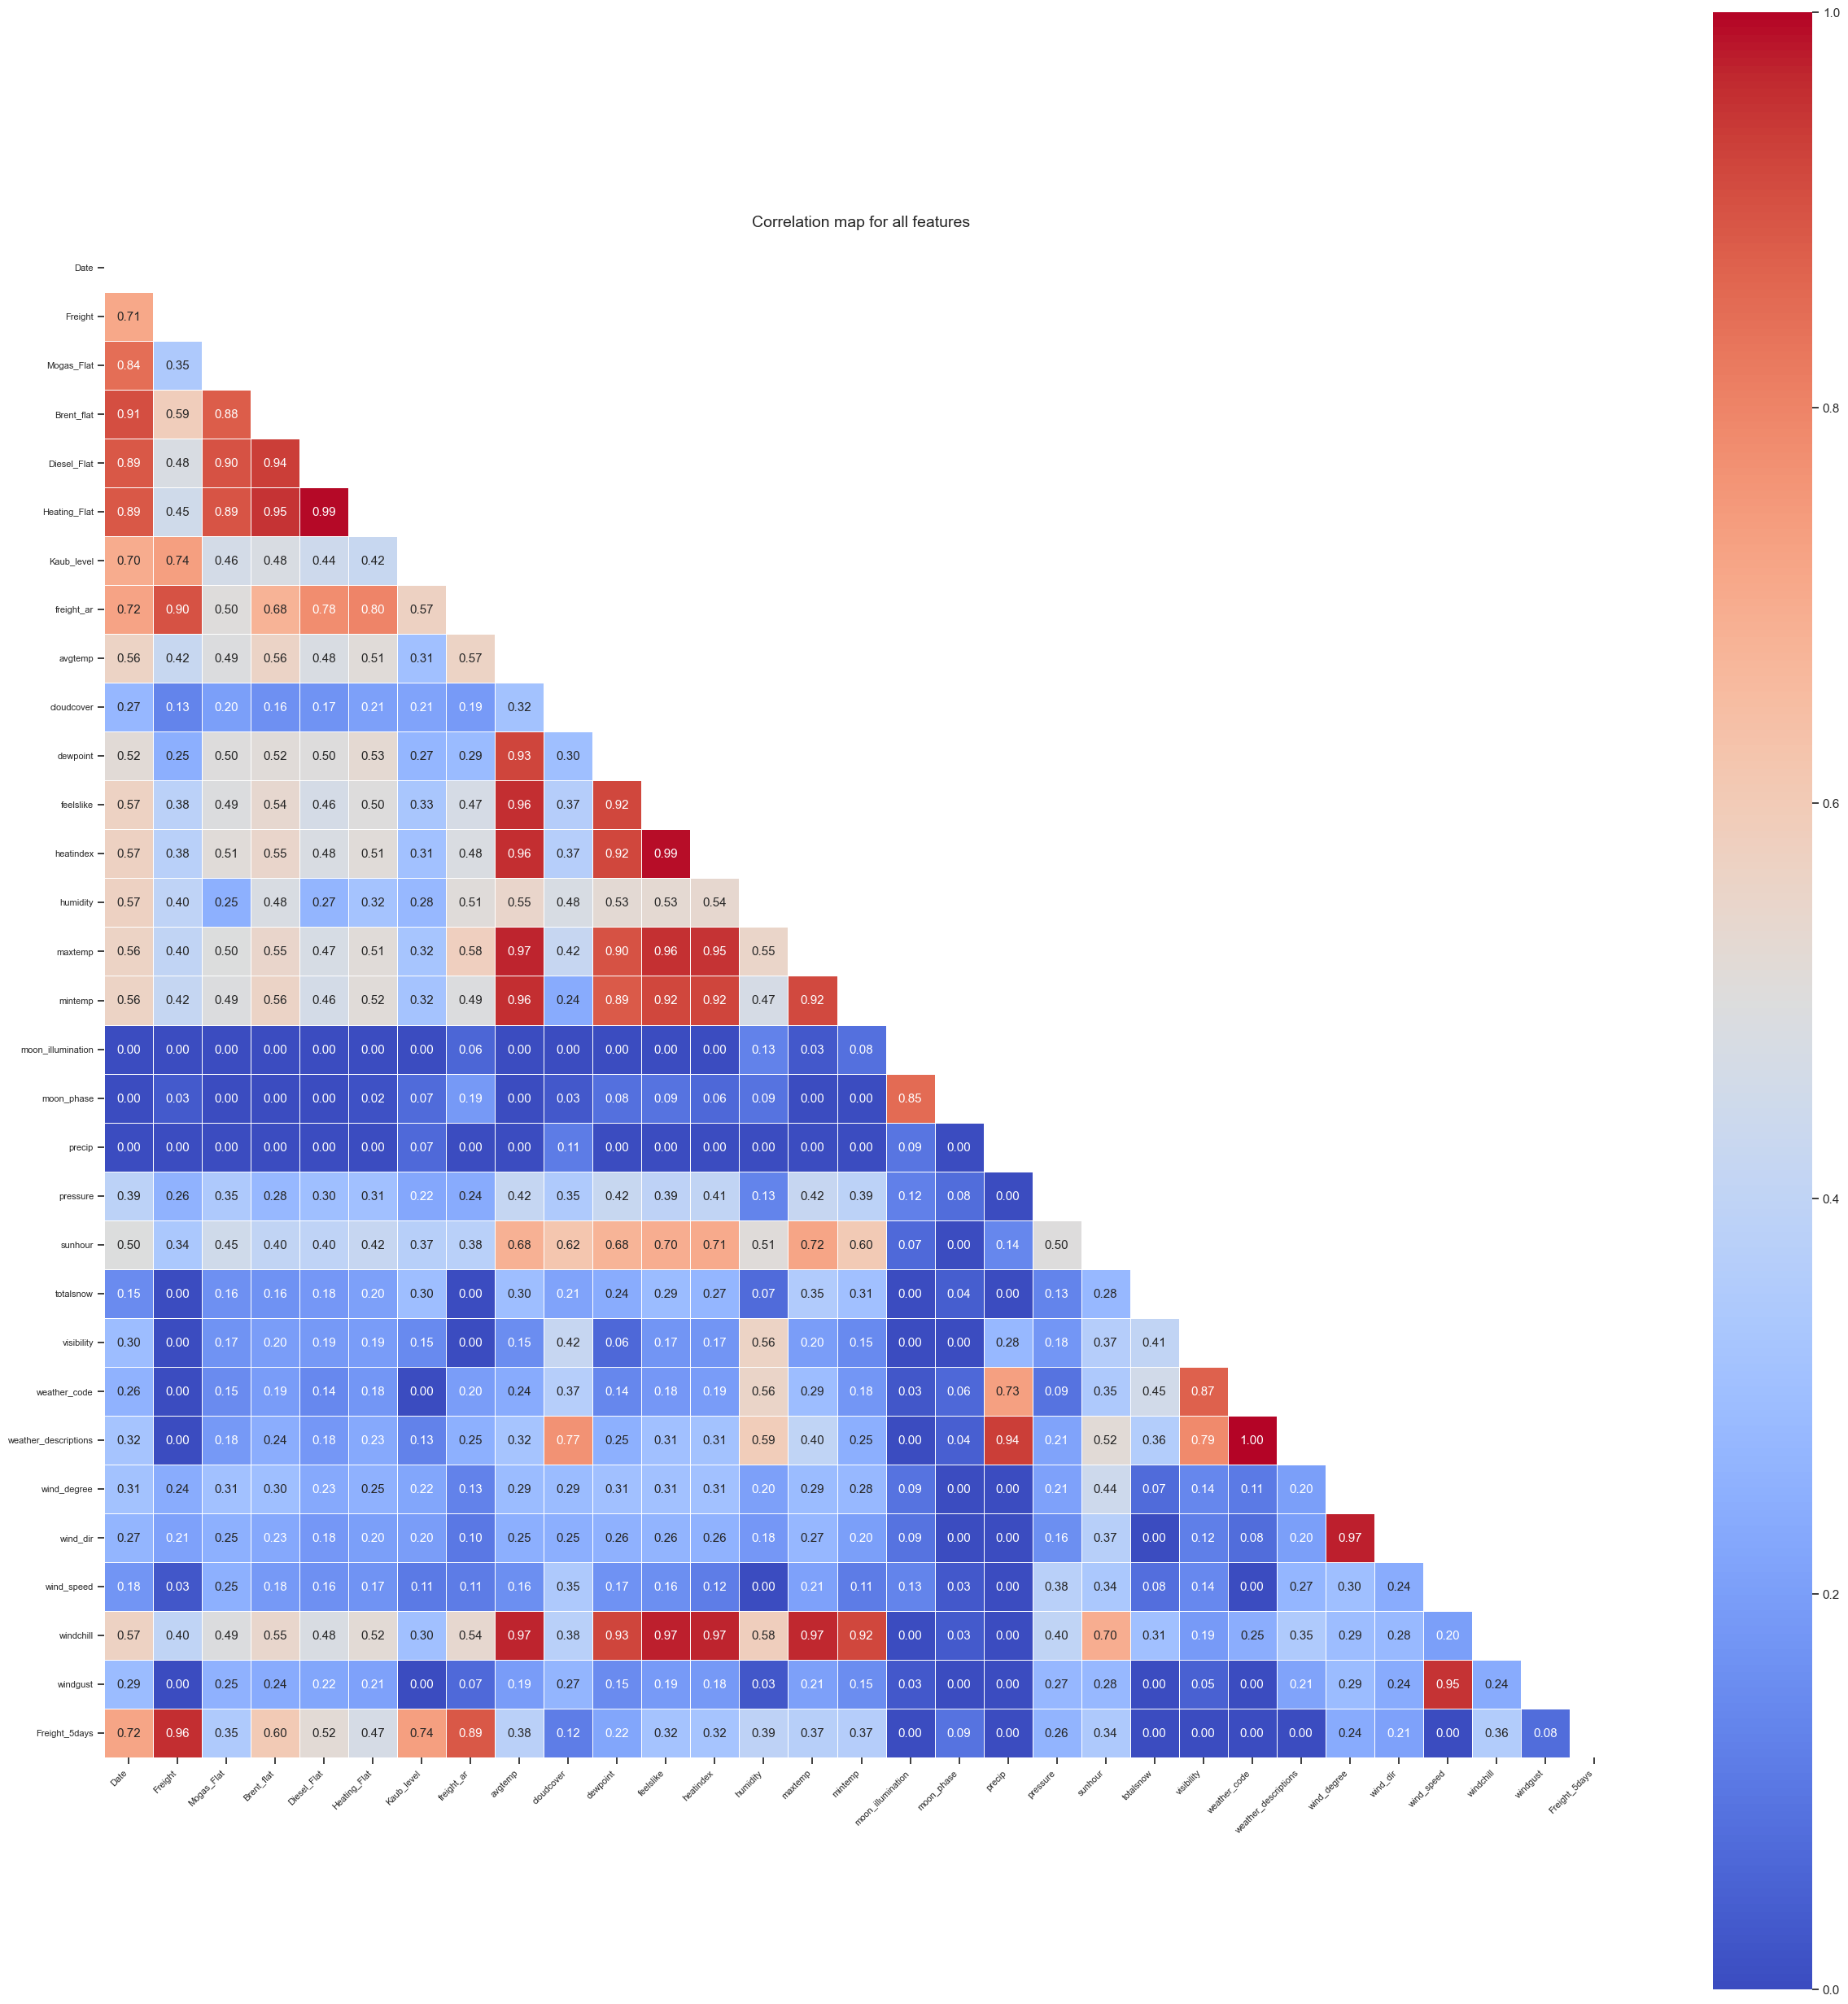

In [299]:
correlation_complete_data = df_complete.copy()

# Garante que é datetime (valores inválidos viram NaT)
correlation_complete_data["Date"] = pd.to_datetime(
    correlation_complete_data["Date"], errors="coerce"
)

# Converte para ordinal, mantendo NaT como NaN
correlation_complete_data["Date"] = correlation_complete_data["Date"].map(
    lambda d: d.toordinal() if pd.notna(d) else np.nan
)

# Calculate Phik matrix (using njobs=1 to prevent Windows crash)
correlation_matrix = correlation_complete_data.phik_matrix(njobs=1)

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# 1. Dynamically scale figure size so cells have enough physical room
n_features = len(correlation_matrix.columns)
fig_size = max(10, n_features * 0.8)
fig, ax = plt.subplots(figsize=(fig_size, fig_size))

# 2. Dynamically shrink text size so numbers fit cleanly inside the cells
font_size = max(5, 14 - (n_features * 0.1))

sns.heatmap(
    correlation_matrix,
    mask=mask,  # Hides the upper triangle
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    # center=0 removed because phik ranges from 0 to 1
    square=True,
    linewidths=0.5,
    annot_kws={"size": font_size},  # Forces annotations to scale down
    ax=ax,
)

# 3. Rotate and adjust tick labels to prevent crowding
plt.xticks(
    rotation=45, ha="right", fontsize=max(8, 12 - int(n_features * 0.15))
)
plt.yticks(rotation=0, fontsize=max(8, 12 - int(n_features * 0.15)))

ax.set_title("Correlation map for all features", fontsize=14, pad=15)
fig.tight_layout()
plt.show()